# Explainability — Why does the model predict pneumonia?

High recall alone does not tell us whether the ResNet-18 trained by `train_optimized.py` looks at the **lungs** or at **shortcuts** such as text markers, hospital labels or image borders. This notebook explains the model's predictions with two methods:

1. **Grad-CAM** — uses the gradients of the predicted class flowing into the last convolutional block (`layer4`) to highlight the regions that drove the decision.
2. **Occlusion sensitivity** — hides one 15×15 patch at a time and measures how much the pneumonia probability drops. It does not depend on gradients, so it cross-checks Grad-CAM.

All code lives in `src/explainability/gradcam.py`; `explain.py` runs the full analysis from the command line.

**Prerequisite:** the dataset extracted to `data/interim/chest_xray` (see `setup.ipynb`) and `pneumonia_resnet18_recall_optimized.pth` in the repo root.

In [1]:
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage

from src.explainability.gradcam import GradCAM, load_resnet18, border_fraction, denormalize, occlusion_sensitivity
from src.dataset import DATA_DIR, test_transform

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
model = load_resnet18("pneumonia_resnet18_recall_optimized.pth", device)

## 1. Run Grad-CAM on the whole test set

This writes per-outcome figures to `reports/figures/explainability/` and a per-image table to `reports/explainability_summary.csv`.

In [2]:
!python explain.py --split test --num-examples 4 --num-occlusion 2 --out-dir reports/figures/explainability --summary reports/explainability_summary.csv

Explained 624 images from data/interim/chest_xray/test
outcome           count   mean border attention
true_positive       388                   0.430
true_negative       163                   0.419
false_positive       71                   0.474
false_negative        2                   0.427
Saved summary to reports/explainability_summary.csv and figures to reports/figures/explainability


## 2. Inspect each outcome group

- **True positives / true negatives:** does the heatmap sit inside the lung fields?
- **False negatives (missed pneumonia):** the most dangerous errors — what did the model look at instead?
- **False positives:** healthy patients flagged as pneumonia — are they driven by real opacities or by artefacts?

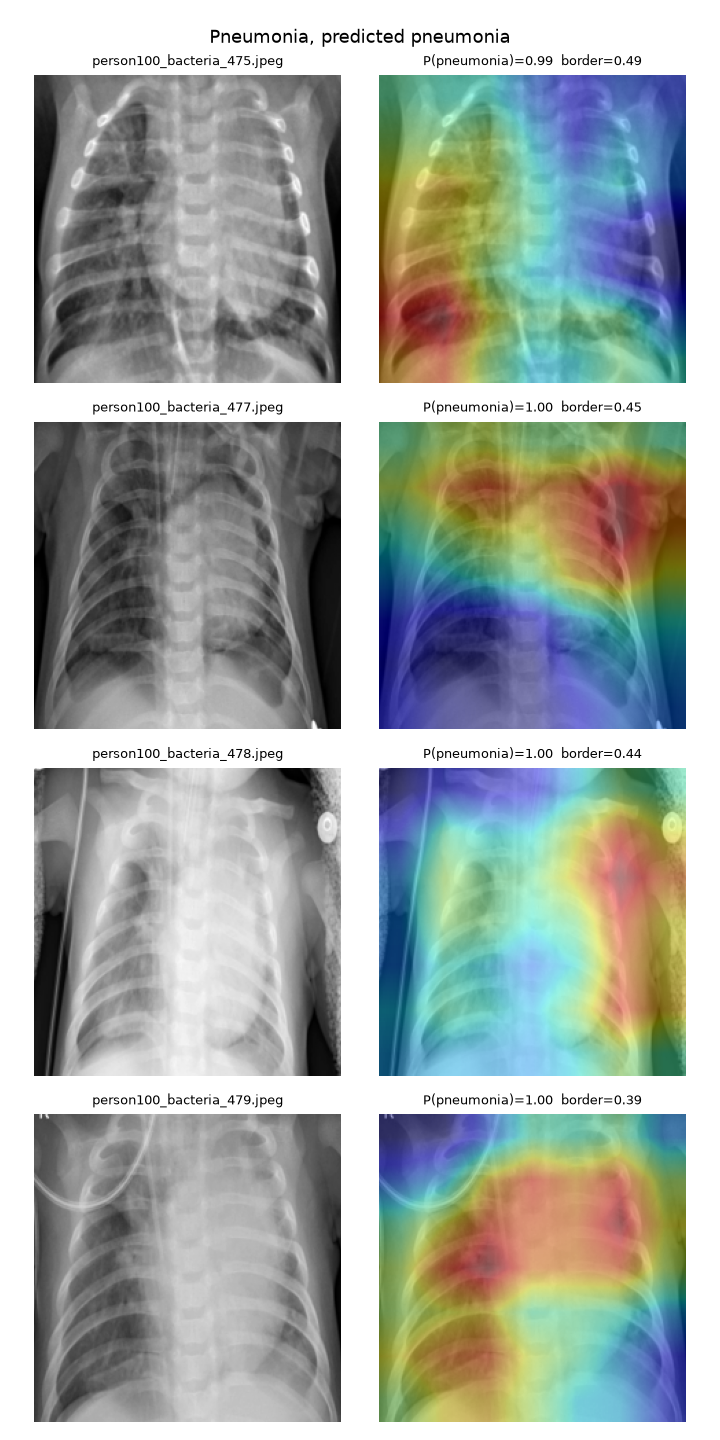

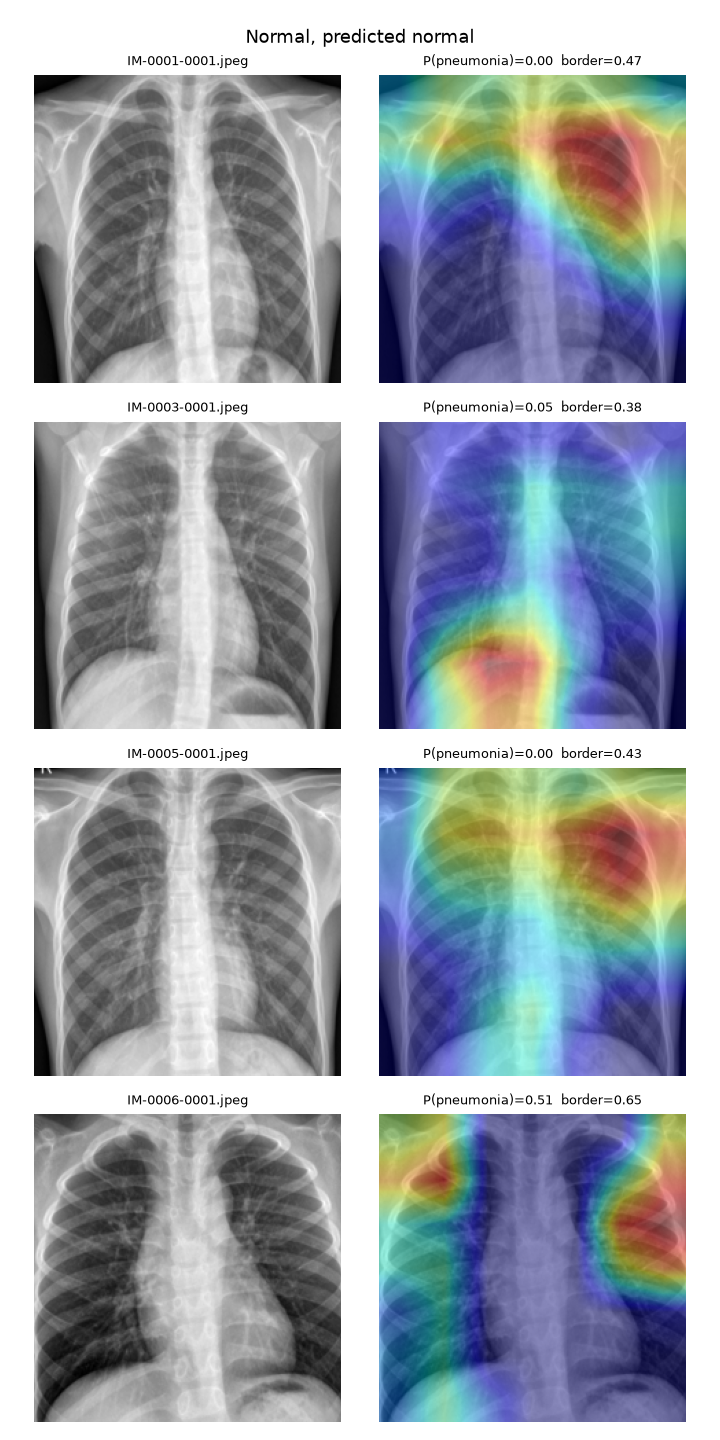

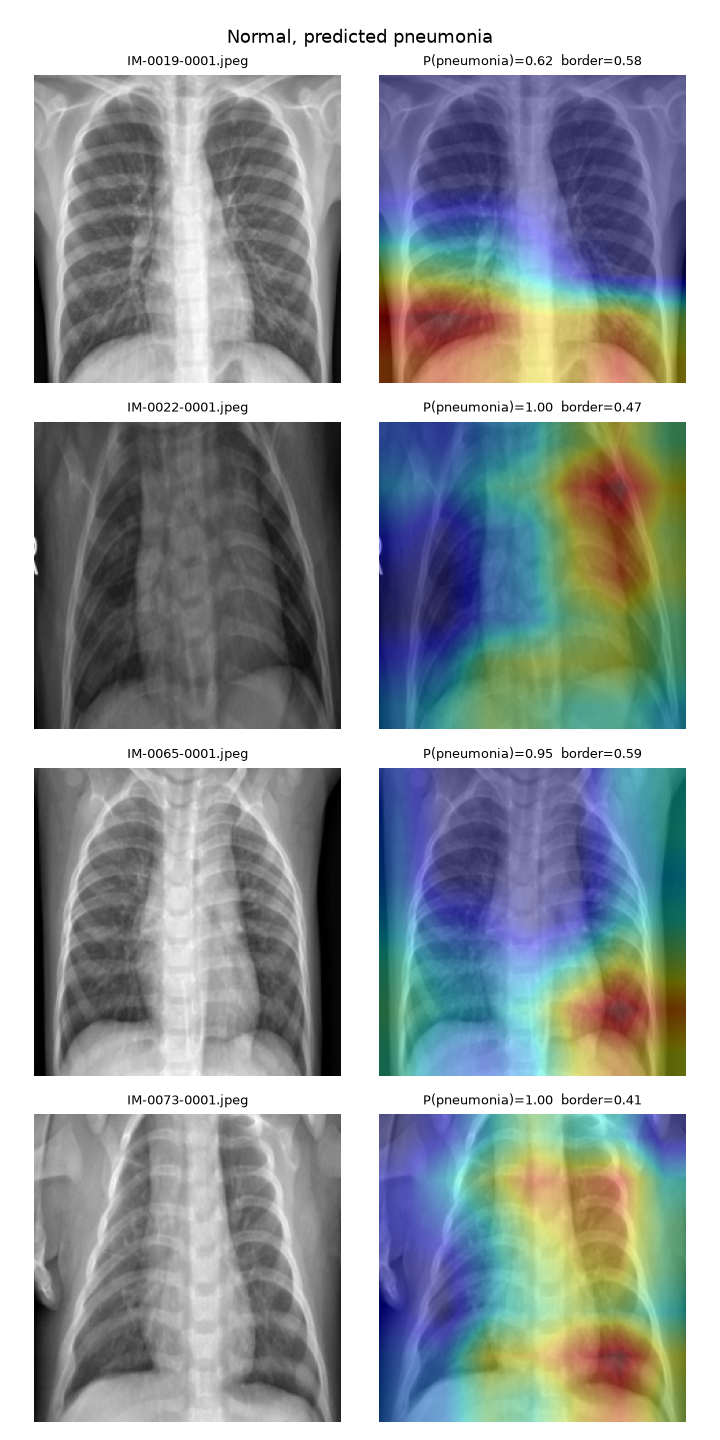

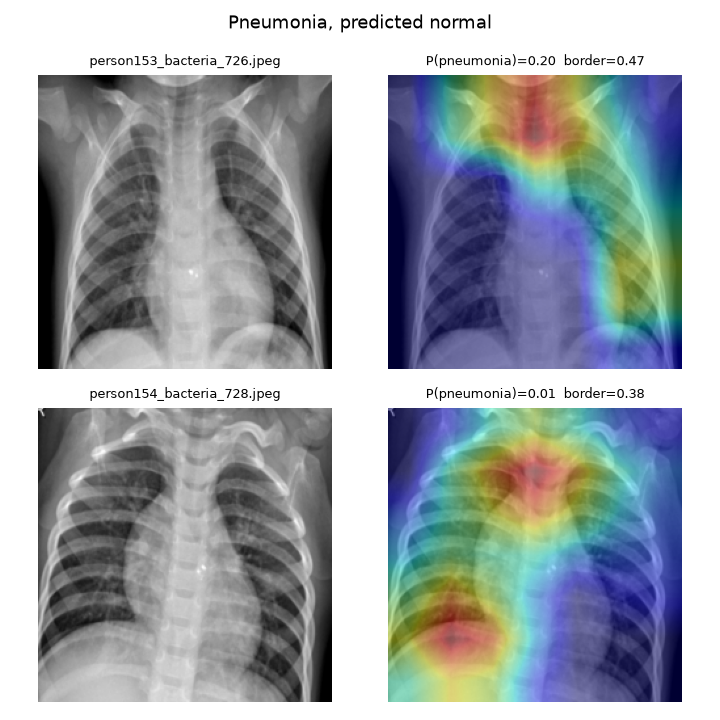

In [3]:
for group in ["true_positive", "true_negative", "false_positive", "false_negative"]:
    try:
        display(ShowImage(f"reports/figures/explainability/{group}.png", width=450))
    except FileNotFoundError:
        print(f"No {group} examples")

## 3. Grad-CAM vs. occlusion

If both methods highlight the same area, the explanation is more trustworthy. Red in the occlusion map means hiding that patch *lowered* the pneumonia probability, i.e. the patch supported a pneumonia prediction.

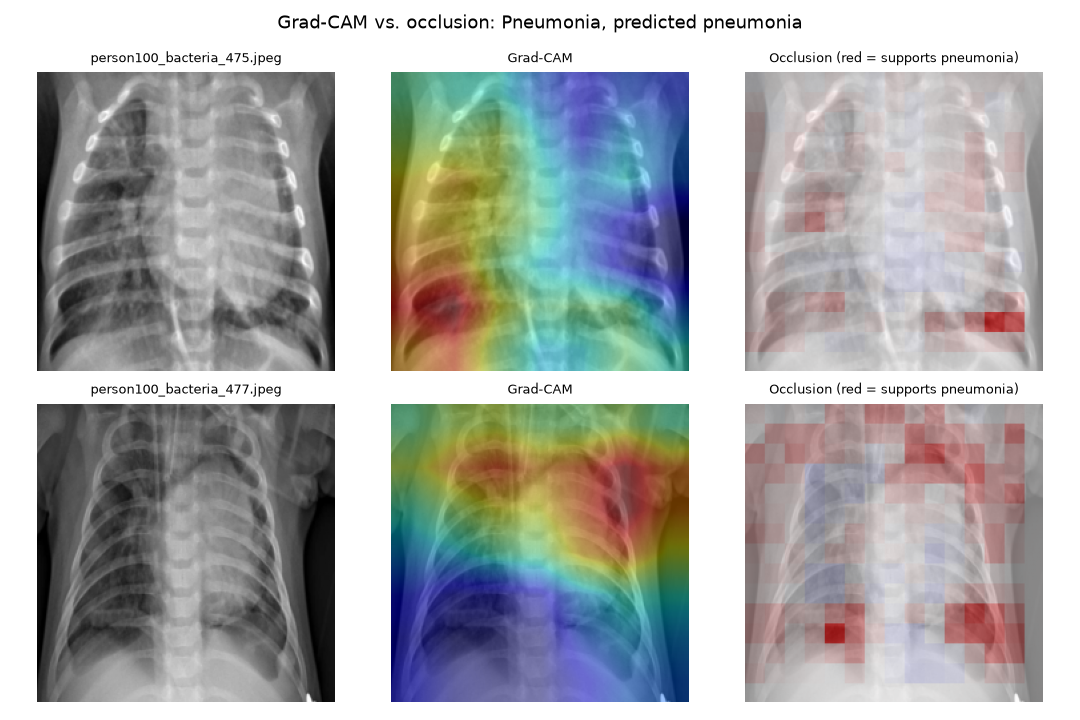

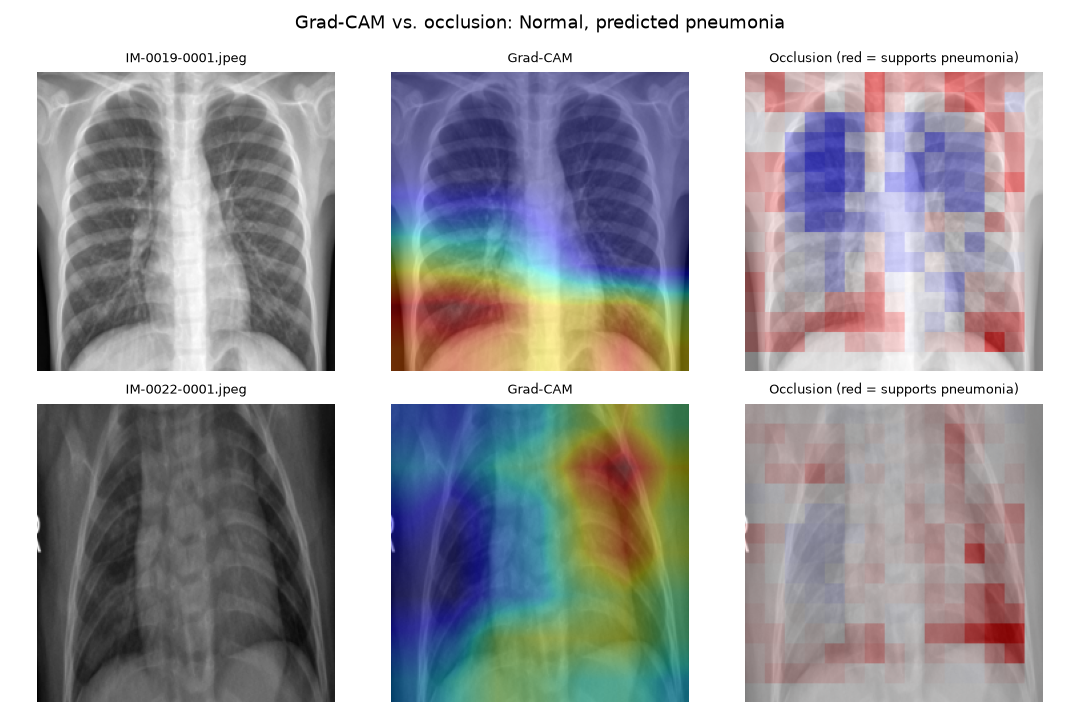

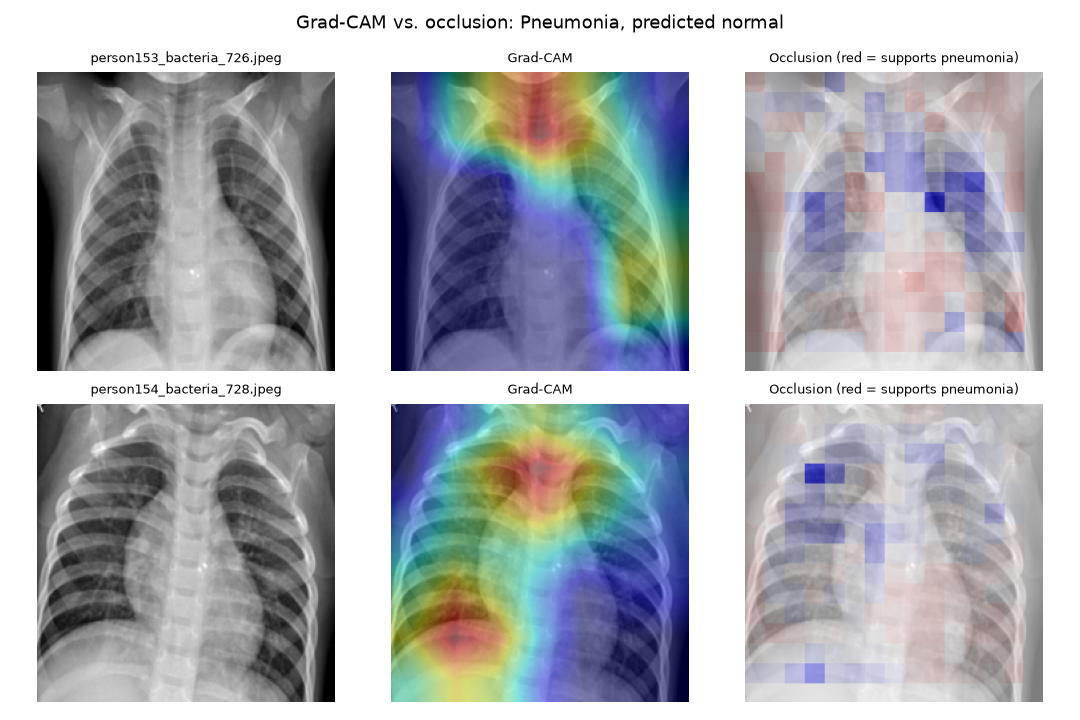

In [4]:
for group in ["true_positive", "false_positive", "false_negative"]:
    try:
        display(ShowImage(f"reports/figures/explainability/occlusion_{group}.png", width=650))
    except FileNotFoundError:
        print(f"No {group} examples")

## 4. Shortcut check: how much attention falls on the image border?

`cam_border_fraction` is the share of the Grad-CAM heatmap lying in the outer 15% band of the image. Lungs are central; markers, labels and scanner edges are near the border.

For reference, a perfectly flat heatmap gives **≈ 0.51** (the band covers 51% of the image area). Values clearly below that mean attention is concentrated centrally; values near or above it suggest the model is using border artefacts.

,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
false_negative,2.0,0.426900,0.067599,0.3791,0.4030,0.4269,0.450800,0.4747
false_positive,71.0,0.474079,0.101774,0.2276,0.4025,0.4712,0.546700,0.6717
true_negative,163.0,0.419445,0.087819,0.1650,0.3537,0.4145,0.475600,0.6472
true_positive,388.0,0.429696,0.052550,0.2173,0.3965,0.4333,0.460425,0.6858


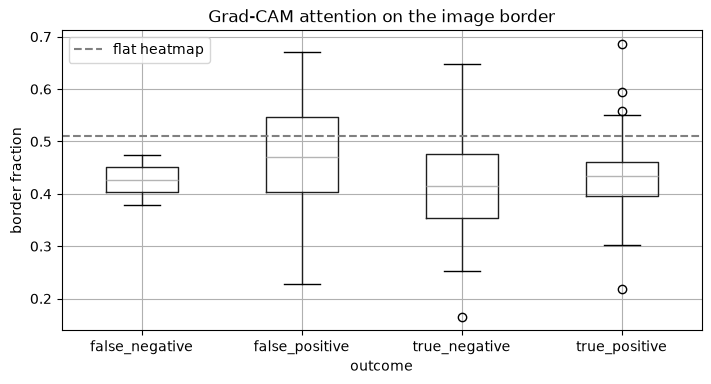

In [5]:
import pandas as pd

summary = pd.read_csv("reports/explainability_summary.csv")
display(summary.groupby("outcome")["cam_border_fraction"].describe())

summary.boxplot(column="cam_border_fraction", by="outcome", figsize=(8, 4))
plt.axhline(0.51, color="gray", linestyle="--", label="flat heatmap")
plt.suptitle("")
plt.title("Grad-CAM attention on the image border")
plt.ylabel("border fraction")
plt.legend()
plt.show()

In [6]:
# Images where the model looks most at the border — inspect these for shortcuts
summary.sort_values("cam_border_fraction", ascending=False).head(10)

,filename,label,prob_pneumonia,prediction,outcome,cam_border_fraction
599,person88_bacteria_439.jpeg,PNEUMONIA,0.5452,PNEUMONIA,true_positive,0.6858
223,NORMAL2-IM-0369-0001.jpeg,NORMAL,0.6659,PNEUMONIA,false_positive,0.6717
47,IM-0077-0001.jpeg,NORMAL,0.5838,PNEUMONIA,false_positive,0.6502
186,NORMAL2-IM-0322-0001.jpeg,NORMAL,0.8187,PNEUMONIA,false_positive,0.6487
3,IM-0006-0001.jpeg,NORMAL,0.5056,NORMAL,true_negative,0.6472
141,NORMAL2-IM-0249-0001.jpeg,NORMAL,0.6043,PNEUMONIA,false_positive,0.6435
190,NORMAL2-IM-0327-0001.jpeg,NORMAL,0.7673,PNEUMONIA,false_positive,0.6325
101,NORMAL2-IM-0111-0001.jpeg,NORMAL,0.0506,NORMAL,true_negative,0.6246
220,NORMAL2-IM-0364-0001.jpeg,NORMAL,0.9394,PNEUMONIA,false_positive,0.6184
171,NORMAL2-IM-0302-0001.jpeg,NORMAL,0.7947,PNEUMONIA,false_positive,0.6140


## 5. Explain a single X-ray

Prediction: PNEUMONIA, P(pneumonia)=0.9941, border attention=0.488
Saved reports/figures/explainability/single_person100_bacteria_475.png


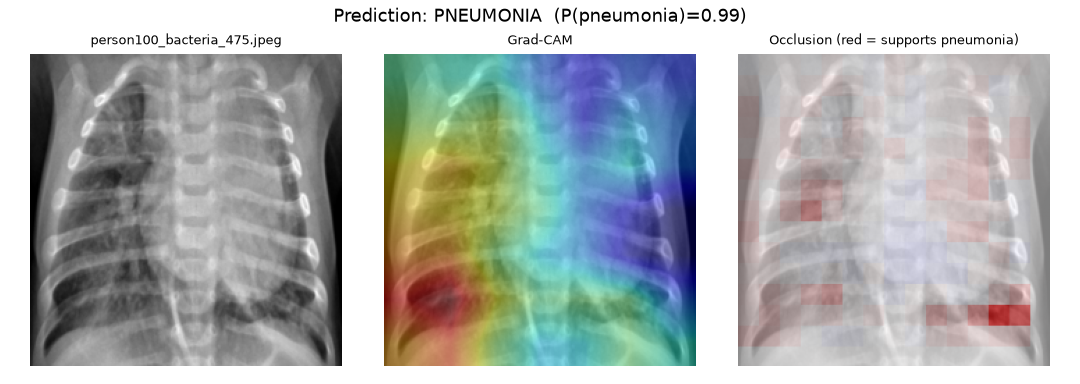

In [7]:
import os
example = os.path.join(DATA_DIR, "test", "PNEUMONIA", sorted(os.listdir(os.path.join(DATA_DIR, "test", "PNEUMONIA")))[0])
!python explain.py --out-dir reports/figures/explainability --image "{example}"
display(ShowImage(f"reports/figures/explainability/single_{os.path.splitext(os.path.basename(example))[0]}.png", width=650))

## 6. What the predictions look like

The explainability table also gives the full confusion matrix and how recall and specificity trade off as the threshold changes.

In [8]:
y = summary["label"] == "PNEUMONIA"
print(summary["outcome"].value_counts())
for t in [0.4, 0.5, 0.7, 0.9, 0.95, 0.99]:
    p = summary["prob_pneumonia"] >= t
    print(f"threshold {t:.2f}: recall {(p & y).sum() / y.sum():.3f}  specificity {(~p & ~y).sum() / (~y).sum():.3f}")

outcome
true_positive     388
true_negative     163
false_positive     71
false_negative      2
Name: count, dtype: int64
threshold 0.40: recall 0.995  specificity 0.688
threshold 0.50: recall 0.995  specificity 0.692
threshold 0.70: recall 0.990  specificity 0.739
threshold 0.90: recall 0.985  specificity 0.812
threshold 0.95: recall 0.979  specificity 0.855
threshold 0.99: recall 0.954  specificity 0.902


## 7. Findings

Results for the current `pneumonia_resnet18_recall_optimized.pth` (trained with the 224×224 center crop, PR #18) on the 624 test images, at the threshold `train_optimized.py` chose on validation (0.52).

**Compared with the previous ResNet-18** (150×150, `pos_weight=3`, threshold 0.4):

| | Previous model | Current model |
|---|---|---|
| Missed pneumonia (false negatives) | 12 | 2 |
| Healthy patients flagged (false positives) | 133 | 71 |
| Recall / specificity | 96.9% / 43.2% | 99.5% / 69.7% |
| Healthy patients flagged with P(pneumonia) ≥ 0.9 | 96 | 44 |
| Images with border attention above a flat heatmap (0.51) | 40.9% | 12.3% |
| False positives with border attention above 0.51 | 91% | 39% |

**1. The model now looks mostly at the lungs.**
Mean border attention is 0.43 for true positives and 0.42 for true negatives, below the 0.51 of a flat heatmap. In the example figures, heatmaps for pneumonia cases cover the lung fields instead of the image edges.

**2. False alarms are the remaining weakness.**
71 of 234 healthy X-rays are still flagged, half of them with P(pneumonia) above 0.94. They have the highest border attention of any group (0.47). In the occlusion examples, the image edges and the area below the diaphragm push towards pneumonia, while the lung fields push towards normal: these decisions are driven by regions outside the lungs.

**3. The two missed cases repeat an old pattern.**
Both are bacterial pneumonia. Both heatmaps are strongest on the trachea and upper mediastinum, as all 12 missed cases were with the previous model. The model is confident they are normal (P = 0.20 and 0.01).

**4. The threshold matters more than it did.**
Test ROC-AUC is 0.975. Choosing the threshold on validation for at least 95% recall (`python evaluate.py --min-recall 0.95`, threshold 0.88) gives 98.5% recall and 81.2% specificity on test: 6 missed cases and 44 false alarms, instead of 2 and 71.

**5. Validation is more optimistic than test.**
Validation specificity is about 99% against 70% on test. Most pneumonia validation images share a patient with a training image, so validation scores should not be quoted as results.

### Recommendations
- Agree on the threshold as a team; 0.88 trades 4 more missed cases for 27 fewer false alarms.
- Split train and validation by patient, then retrain and re-run this notebook.
- Review the false-positive figures with someone who reads chest X-rays before deployment.